In [1]:
import pandas as pd

In [2]:
import pandas as pd

df = pd.read_csv('/content/retail_sales_dataset.csv')

display(df.head())

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [3]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(1000, 9)

Column Names:
Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB

Statistical Summary:


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000



Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [4]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check dataset after cleaning
print("\nDataset shape after cleaning:")
print(df.shape)

display(df.head())


Duplicate rows: 0

Missing values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Dataset shape after cleaning:
(1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [6]:
print(df.columns.tolist())

['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


In [7]:
# Total sales revenue
print("Total Revenue:", df["Total Amount"].sum())

# Total quantity sold
print("Total Quantity Sold:", df["Quantity"].sum())

# Average sales amount
print("Average Sales:", round(df["Total Amount"].mean(), 2))

# Top 5 transactions
display(df.sort_values("Total Amount", ascending=False).head())

Total Revenue: 456000
Total Quantity Sold: 2514
Average Sales: 456.0


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
945,946,2023-05-08,CUST946,Male,62,Electronics,4,500,2000
71,72,2023-05-23,CUST072,Female,20,Electronics,4,500,2000
14,15,2023-01-16,CUST015,Female,42,Electronics,4,500,2000
576,577,2023-02-13,CUST577,Male,21,Beauty,4,500,2000
571,572,2023-04-20,CUST572,Male,31,Clothing,4,500,2000


Sales by Category:
Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64

Highest Sales Category:
Electronics


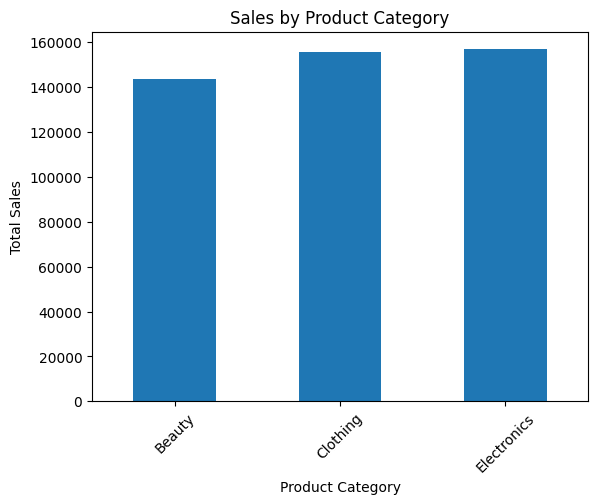

In [8]:
# Sales by product category
category_sales = df.groupby("Product Category")["Total Amount"].sum()

print("Sales by Category:")
print(category_sales)

# Highest sales category
print("\nHighest Sales Category:")
print(category_sales.idxmax())

# Bar chart
import matplotlib.pyplot as plt

category_sales.plot(kind="bar")
plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()


Monthly Sales:
Month
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64


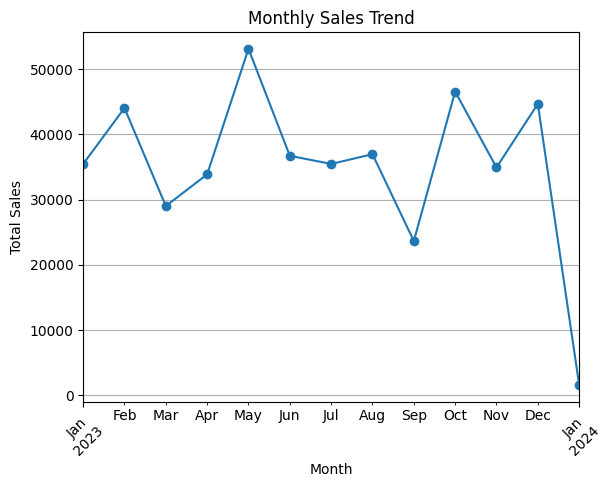

In [9]:
# Convert Date column to date format
df["Date"] = pd.to_datetime(df["Date"])

# Extract month
df["Month"] = df["Date"].dt.to_period("M")

# Calculate monthly sales
monthly_sales = df.groupby("Month")["Total Amount"].sum()

print("Monthly Sales:")
print(monthly_sales)

# Line chart
monthly_sales.plot(kind="line", marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

Sales by Gender:
Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64

Transactions by Gender:
Gender
Female    510
Male      490
Name: count, dtype: int64

Average Customer Age: 41.39


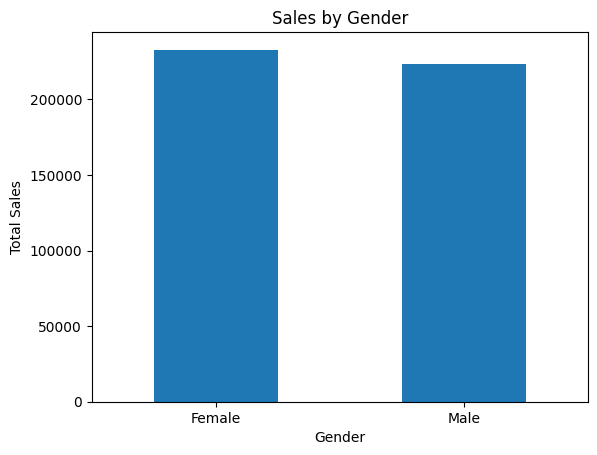

In [10]:
# Gender-wise sales
gender_sales = df.groupby("Gender")["Total Amount"].sum()

print("Sales by Gender:")
print(gender_sales)

# Number of transactions by gender
print("\nTransactions by Gender:")
print(df["Gender"].value_counts())

# Average age of customers
print("\nAverage Customer Age:", round(df["Age"].mean(), 2))

# Gender-wise sales chart
gender_sales.plot(kind="bar")
plt.title("Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.show()

In [11]:
print("RETAIL SALES ANALYSIS REPORT")
print("=" * 35)

print("\n1. Dataset Overview")
print("Total Transactions:", len(df))
print("Total Customers:", df["Customer ID"].nunique())
print("Product Categories:", df["Product Category"].nunique())

print("\n2. Sales Summary")
print("Total Revenue:", df["Total Amount"].sum())
print("Average Transaction Amount:", round(df["Total Amount"].mean(), 2))

print("\n3. Best Performing Category")
print(category_sales.sort_values(ascending=False))

print("\n4. Customer Insights")
print("Average Customer Age:", round(df["Age"].mean(), 2))
print("Sales by Gender:")
print(gender_sales)

print("\n5. Conclusion")
print("Sales data was analysed using Python and Pandas.")
print("Category-wise and monthly trends were visualized.")
print("Customer patterns were explored to identify insights.")

RETAIL SALES ANALYSIS REPORT

1. Dataset Overview
Total Transactions: 1000
Total Customers: 1000
Product Categories: 3

2. Sales Summary
Total Revenue: 456000
Average Transaction Amount: 456.0

3. Best Performing Category
Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

4. Customer Insights
Average Customer Age: 41.39
Sales by Gender:
Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64

5. Conclusion
Sales data was analysed using Python and Pandas.
Category-wise and monthly trends were visualized.
Customer patterns were explored to identify insights.
